In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE

Données chargées avec succès !


/tmp/ipython-input-1986560956.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Target', palette='viridis')


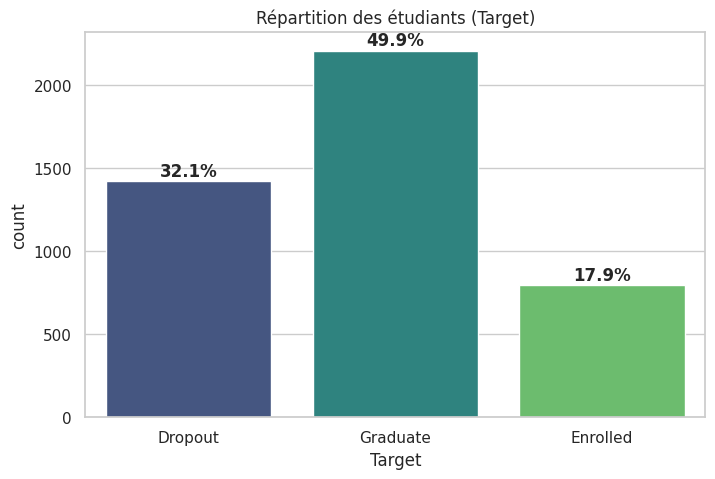

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


/tmp/ipython-input-1986560956.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='Target', y='Curricular units 1st sem (grade)', palette='Set2')
/tmp/ipython-input-1986560956.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='Target', y='Curricular units 2nd sem (grade)', palette='Set2')


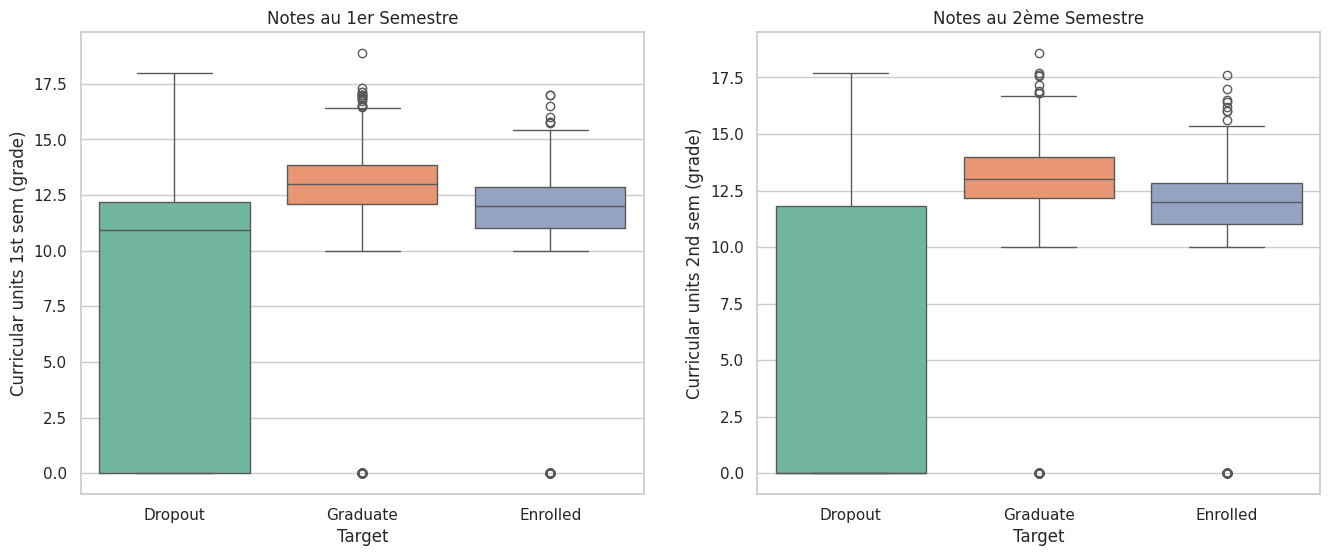

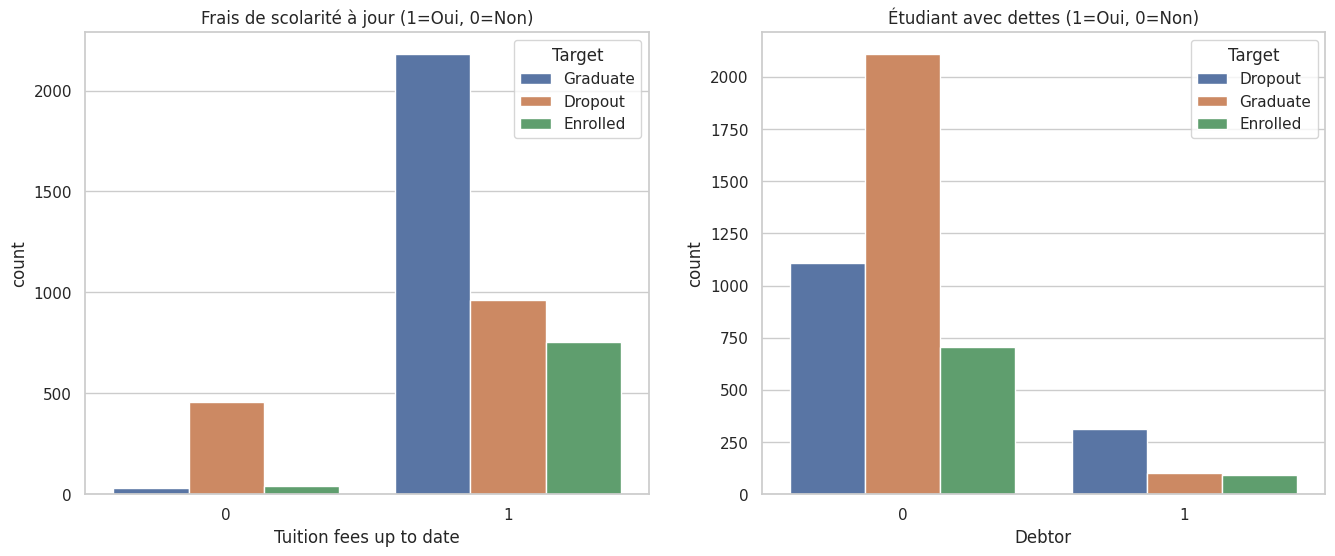

/tmp/ipython-input-1986560956.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Femme', 'Homme'])


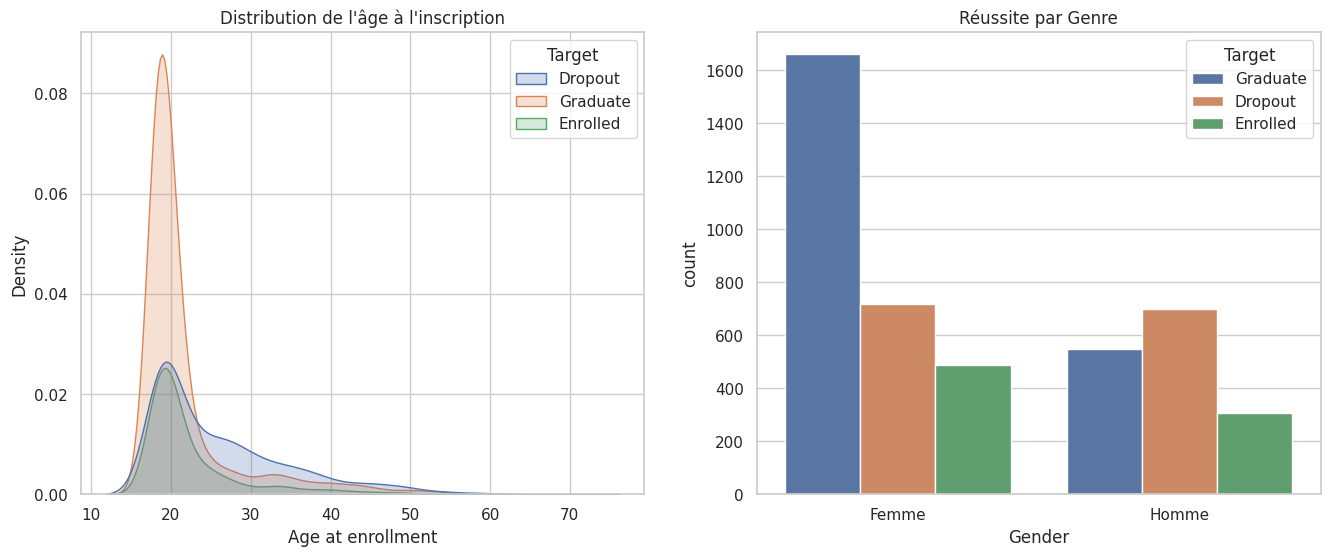

<Figure size 1000x600 with 0 Axes>

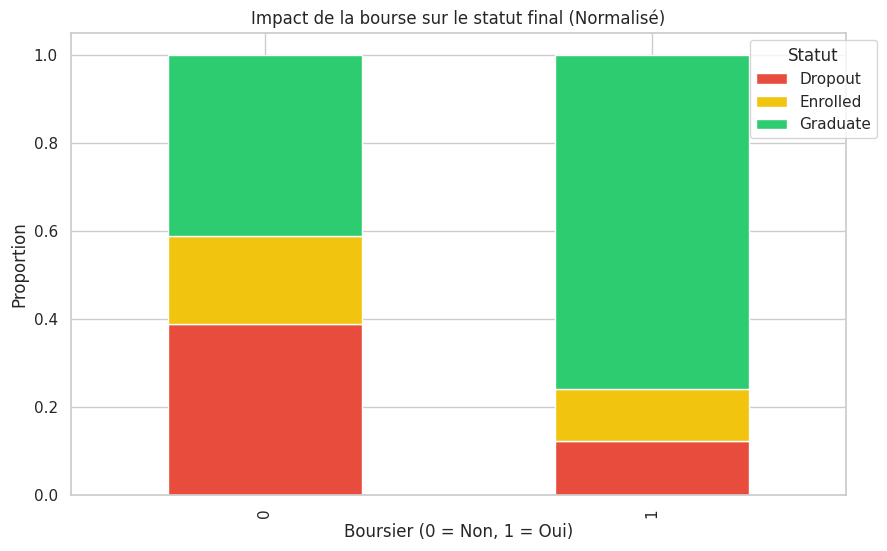

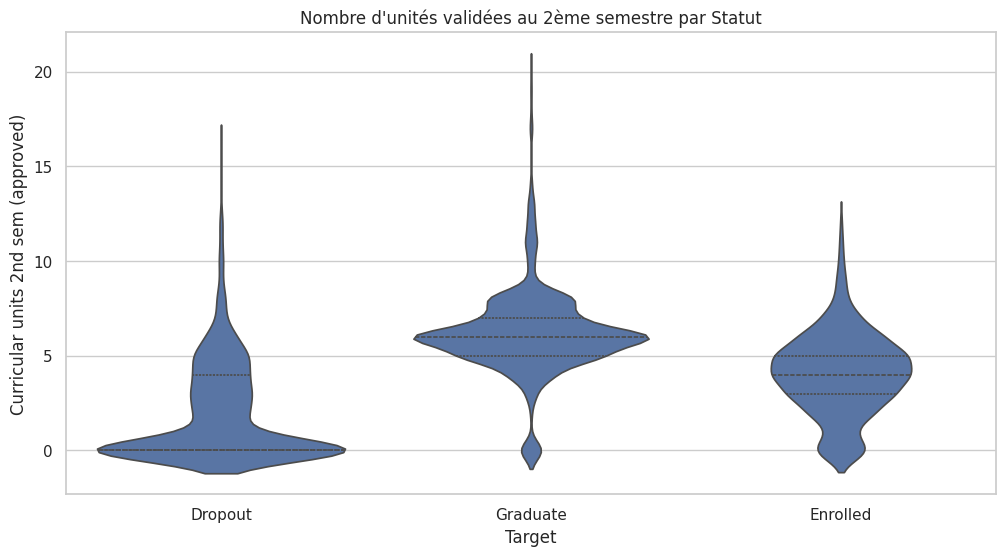

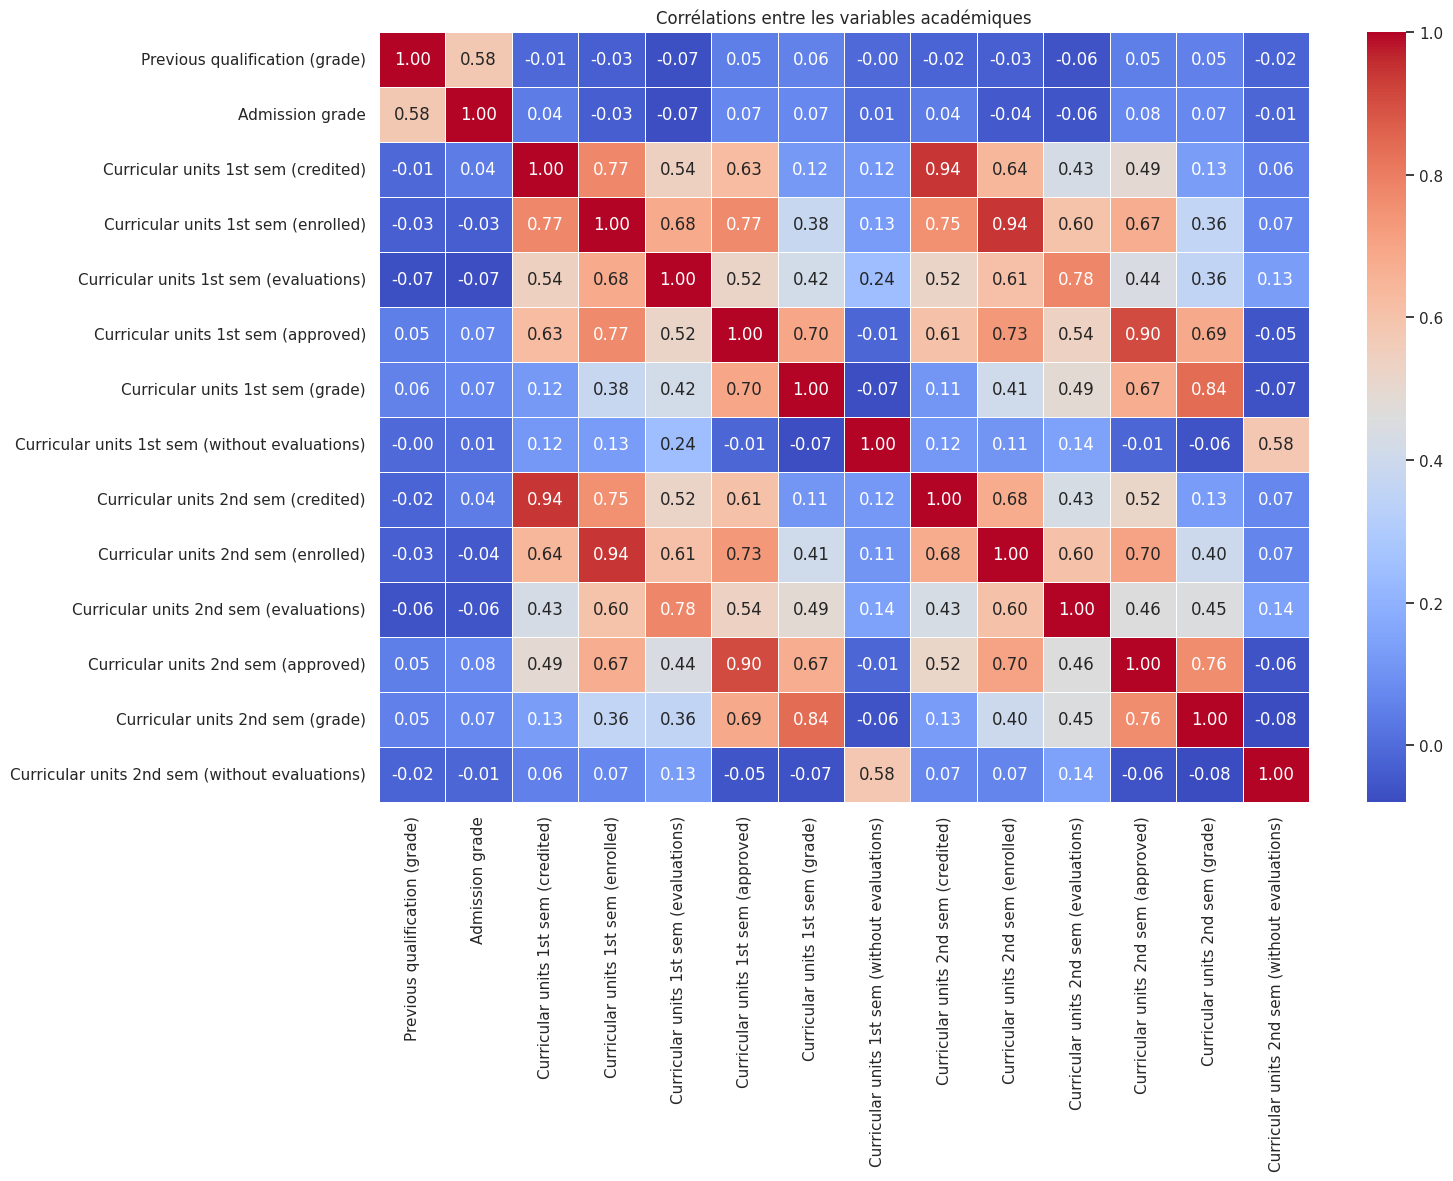

/tmp/ipython-input-1986560956.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='Target', y='Unemployment rate', palette='cool')
/tmp/ipython-input-1986560956.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='Target', y='GDP', palette='cool')


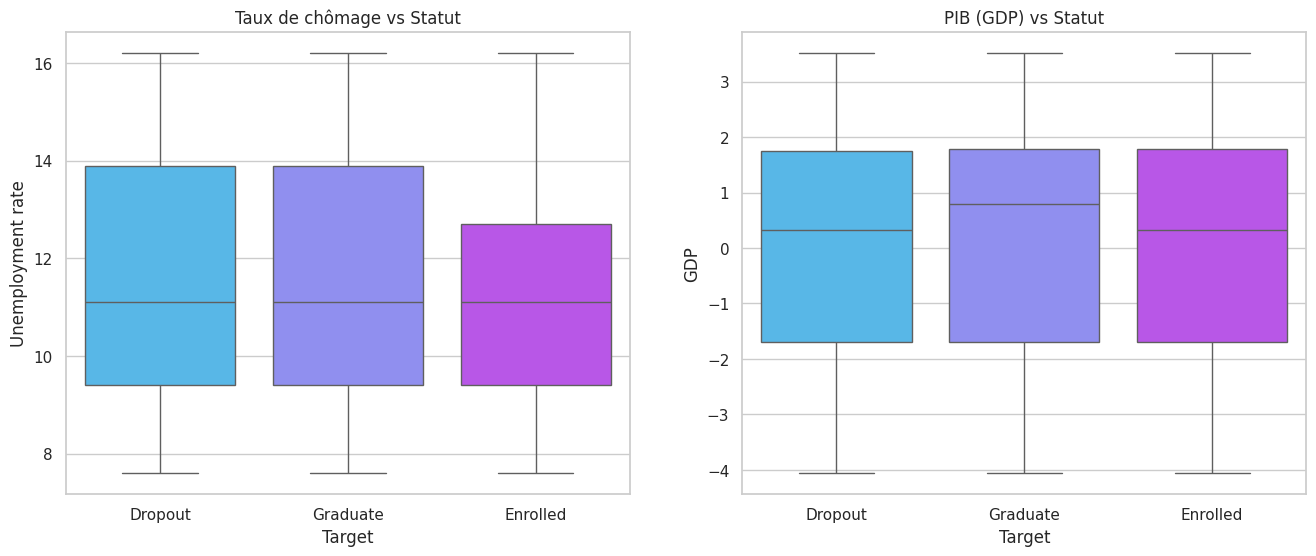

Valeurs manquantes :
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                         

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000



Répartition par genre :
Gender
0    2868
1    1556
Name: count, dtype: int64


In [3]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Configuration des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Chargement des données (vérifie bien le nom de ton fichier)
# Le séparateur est ';' selon ton texte
df = pd.read_csv('Predict Student Dropout and Academic Success.csv', sep=';')

# Nettoyage rapide du nom des colonnes (enlève les espaces blancs éventuels)
df.columns = df.columns.str.strip()

print("Données chargées avec succès !")
df.head()

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Target', palette='viridis')

# Ajout des pourcentages sur les barres
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='center', weight='bold')

plt.title('Répartition des étudiants (Target)')
plt.show()

print(df['Target'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Notes Semestre 1
sns.boxplot(ax=axes[0], data=df, x='Target', y='Curricular units 1st sem (grade)', palette='Set2')
axes[0].set_title('Notes au 1er Semestre')

# Notes Semestre 2
sns.boxplot(ax=axes[1], data=df, x='Target', y='Curricular units 2nd sem (grade)', palette='Set2')
axes[1].set_title('Notes au 2ème Semestre')

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Frais de scolarité à jour
sns.countplot(ax=axes[0], data=df, x='Tuition fees up to date', hue='Target')
axes[0].set_title('Frais de scolarité à jour (1=Oui, 0=Non)')

# Étudiants endettés
sns.countplot(ax=axes[1], data=df, x='Debtor', hue='Target')
axes[1].set_title('Étudiant avec dettes (1=Oui, 0=Non)')

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution de l'âge
sns.kdeplot(ax=axes[0], data=df, x='Age at enrollment', hue='Target', fill=True)
axes[0].set_title('Distribution de l\'âge à l\'inscription')

# Genre (Dans ce dataset 1=Homme, 0=Femme souvent)
sns.countplot(ax=axes[1], data=df, x='Gender', hue='Target')
axes[1].set_title('Réussite par Genre')
axes[1].set_xticklabels(['Femme', 'Homme'])

plt.show()

plt.figure(figsize=(10, 6))
ct = pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index')
ct.plot(kind='bar', stacked=True, color=['#e74c3c', '#f1c40f', '#2ecc71'])
plt.title('Impact de la bourse sur le statut final (Normalisé)')
plt.ylabel('Proportion')
plt.xlabel('Boursier (0 = Non, 1 = Oui)')
plt.legend(title='Statut', bbox_to_anchor=(1.05, 1))
plt.show()

plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='Target', y='Curricular units 2nd sem (approved)', inner="quart")
plt.title('Nombre d\'unités validées au 2ème semestre par Statut')
plt.show()

# On sélectionne uniquement les colonnes numériques
cols_academiques = [col for col in df.columns if 'Curricular' in col or 'grade' in col.lower()]
corr = df[cols_academiques].corr()

plt.figure(figsize=(15, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Corrélations entre les variables académiques')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(ax=axes[0], data=df, x='Target', y='Unemployment rate', palette='cool')
axes[0].set_title('Taux de chômage vs Statut')

sns.boxplot(ax=axes[1], data=df, x='Target', y='GDP', palette='cool')
axes[1].set_title('PIB (GDP) vs Statut')

plt.show()

# Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# Afficher les types de colonnes
print("\nTypes de données :")
print(df.dtypes)

# Statistiques descriptives
print("\nStatistiques descriptives :")
display(df.describe()) # Utilise display pour un joli tableau dans Jupyter

# Compte pour la colonne Gender
print("\nRépartition par genre :")
print(df['Gender'].value_counts())





In [4]:
cols_to_drop = ['Nacionality']
df_cleaned = df.drop(columns=cols_to_drop)

print(f"Ancien nombre de colonnes : {df.shape[1]}")
print(f"Nouveau nombre de colonnes : {df_cleaned.shape[1]}")


from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_cleaned['Target'] = le.fit_transform(df_cleaned['Target'])

mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapping de la variable Target :", mapping)


X = df_cleaned.drop(columns=['Target'])
y = df_cleaned['Target']


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train :", X_train.shape)
print("Test :", X_test.shape)


# Si tu n'as pas imblearn, lance : !pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisation effectuée")

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("Avant SMOTE :", y_train.value_counts().to_dict())
print("Après SMOTE :", pd.Series(y_train_resampled).value_counts().to_dict())

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled, y_train
)

print("Avant SMOTE :", y_train.value_counts().to_dict())
print("Après SMOTE :", pd.Series(y_train_resampled).value_counts().to_dict())


# Après avoir fait toutes les transformations (suppression doublons, encodage, etc.)
df.to_csv('Student_Data_Cleaned2.csv', index=False)

print("Le fichier 'Student_Data_Cleaned.csv' a été créé avec succès !")



Ancien nombre de colonnes : 37
Nouveau nombre de colonnes : 36
Mapping de la variable Target : {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}
Train : (3539, 35)
Test : (885, 35)
Normalisation effectuée
Avant SMOTE : {2: 1767, 0: 1137, 1: 635}
Après SMOTE : {2: 1767, 0: 1767, 1: 1767}
Avant SMOTE : {2: 1767, 0: 1137, 1: 635}
Après SMOTE : {2: 1767, 0: 1767, 1: 1767}
Le fichier 'Student_Data_Cleaned.csv' a été créé avec succès !


/tmp/ipython-input-10111435.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Variable', data=feature_importance_df.head(15), palette='magma')


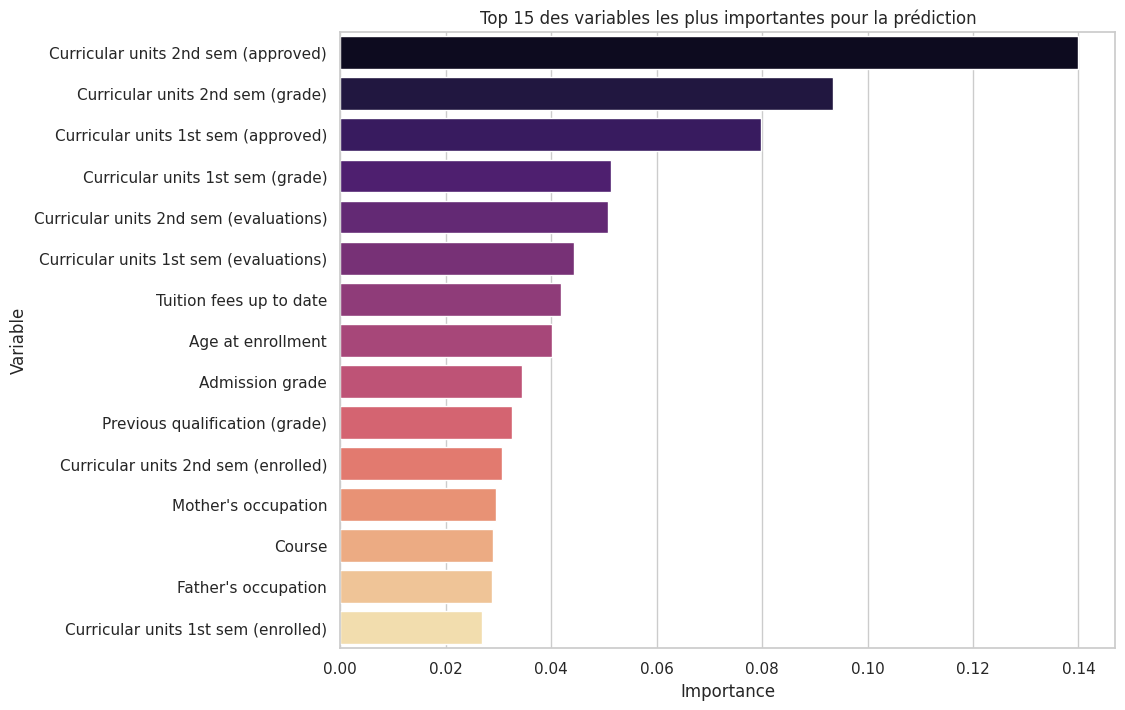


Variables sélectionnées  :
['Course', 'Previous qualification (grade)', "Mother's occupation", "Father's occupation", 'Admission grade', 'Tuition fees up to date', 'Age at enrollment', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'GDP']

Le fichier 'Student_Data_Selected_Features.csv' a été créé avec succès !


In [5]:
df_final = pd.read_csv('Student_Data_Cleaned2.csv')
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
importances = rf.feature_importances_
feature_importance_df = pd.DataFrame({
    'Variable': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Variable', data=feature_importance_df.head(15), palette='magma')
plt.title('Top 15 des variables les plus importantes pour la prédiction')
plt.show()
selector = RFE(rf, n_features_to_select=15, step=1)
selector = selector.fit(X_train_resampled, y_train_resampled)
features_finales = X.columns[selector.support_].tolist()
print("\nVariables sélectionnées  :")
print(features_finales)
X_train_final = pd.DataFrame(X_train_resampled, columns=X.columns)[features_finales]
X_test_final = pd.DataFrame(X_test_scaled, columns=X.columns)[features_finales]
X_train_final['Target'] = y_train_resampled
X_train_final.to_csv('Student_Data_Selected_Features.csv', index=False)

print("\nLe fichier 'Student_Data_Selected_Features.csv' a été créé avec succès !")

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Bibliothèques ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
!pip install catboost -q
from catboost import CatBoostClassifier

# ==========================================================
# 1. CHARGEMENT ET RÉCUPÉRATION DU SPLIT GROUPE
# ==========================================================
df = pd.read_csv('Student_Data_Selected_Features.csv')
X = df.drop('Target', axis=1)
y = df['Target']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# On sépare le TEST set AVANT de faire SMOTE (Anti-Data Leakage)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# ==========================================================
# 2. TRAITEMENT SMOTE (Focus sur Absences et Moyennes)
# ==========================================================
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_raw, y_train)

# Version STANDARDISÉE (uniquement pour la Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test_raw)

print(f"✅ Data Ready: {X_train_res.shape[0]} étudiants pour l'apprentissage.")

# ==========================================================
# 3. LE GRAND BENCHMARK : Baseline + Bagging + Boosting
# ==========================================================
# Configuration Modèle : (Instance, Est-ce qu'on scale ?)
config_models = {
    "Régression Logistique (Baseline)": (LogisticRegression(max_iter=5000), True),
    "Random Forest (Bagging)": (RandomForestClassifier(n_estimators=100, random_state=42), False),
    "AdaBoost": (AdaBoostClassifier(n_estimators=100, random_state=42), False),
    "Gradient Boosting": (GradientBoostingClassifier(max_depth=5, random_state=42), False),
    "XGBoost": (XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6), False),
    "LightGBM": (LGBMClassifier(n_estimators=200, learning_rate=0.05, verbose=-1), False),
    "CatBoost": (CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, verbose=0), False)
}

resultats = []

print("🚀 Duel des 7 algorithmes en cours...\n")

for nom, (m, must_scale) in config_models.items():
    # Sélection de la donnée appropriée
    X_tr = X_train_scaled if must_scale else X_train_res
    X_ts = X_test_scaled if must_scale else X_test_raw

    m.fit(X_tr, y_train_res)
    y_pred = m.predict(X_ts)
    y_prob = m.predict_proba(X_ts)

    resultats.append({
        "Algorithme": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "ROC-AUC (Macro)": roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
    })

# Création du tableau final
df_final = pd.DataFrame(resultats).sort_values(by='ROC-AUC (Macro)', ascending=False)
display(df_final)

✅ Data Ready: 4242 étudiants pour l'apprentissage.
🚀 Duel des 7 algorithmes en cours...



,Algorithme,Accuracy,F1-Score,Recall,ROC-AUC (Macro)
5,LightGBM,0.828464,0.827966,0.828464,0.946252
1,Random Forest (Bagging),0.828464,0.828327,0.828464,0.942000
4,XGBoost,0.815269,0.815084,0.815269,0.936933
6,CatBoost,0.812441,0.812128,0.812441,0.936355
3,Gradient Boosting,0.822809,0.822722,0.822809,0.935689
0,Régression Logistique (Baseline),0.720075,0.720621,0.720075,0.875957
2,AdaBoost,0.726673,0.727502,0.726673,0.870110


⌛ Génération des matrices de confusion pour les 7 modèles...


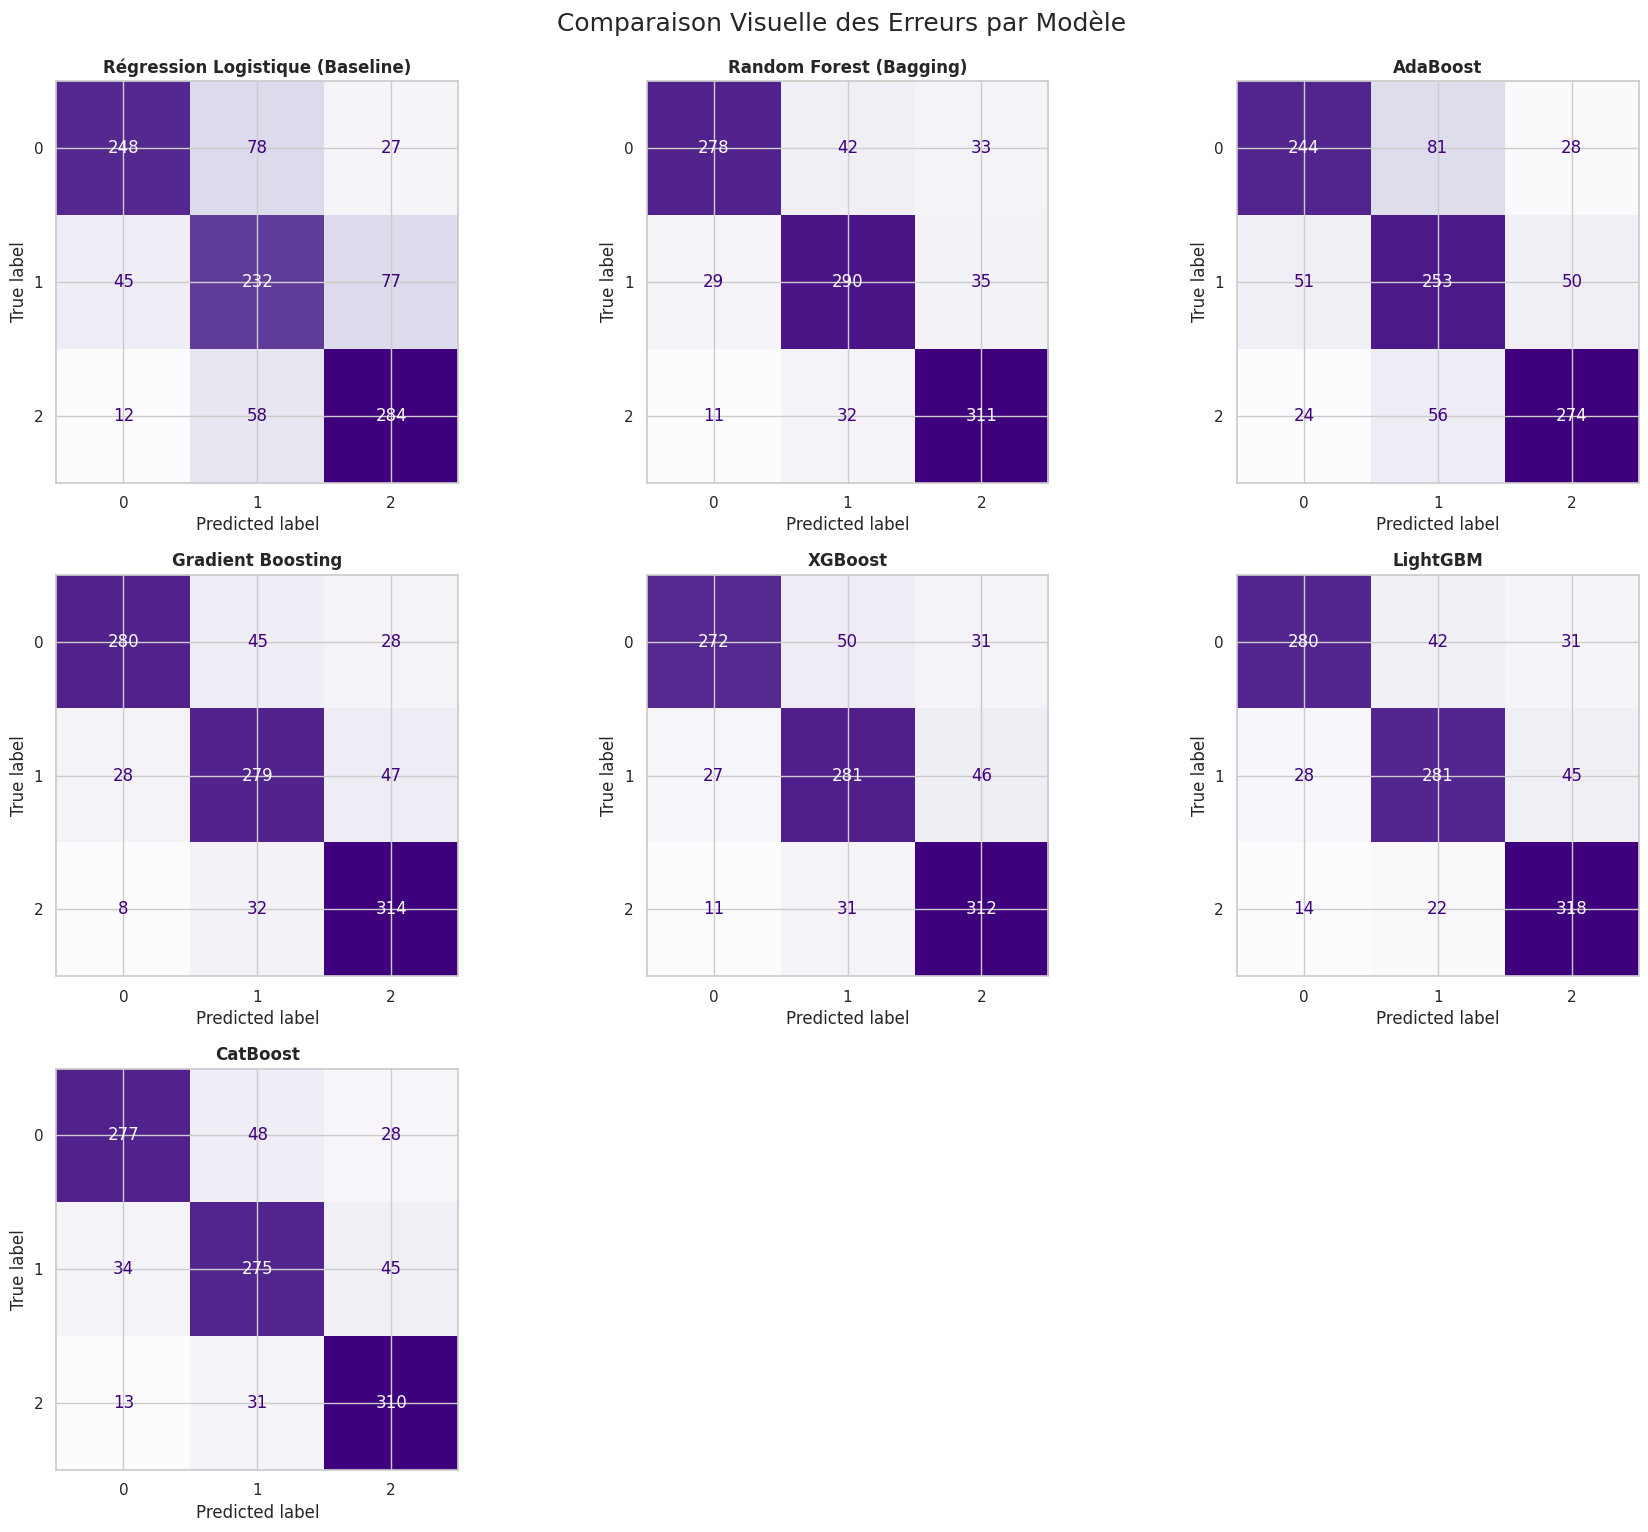

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# On prépare une grille de 3 colonnes et 3 lignes
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15))
axes = axes.flatten()

print("⌛ Génération des matrices de confusion pour les 7 modèles...")

# On parcourt le dictionnaire de configuration (all_models ou config_models)
for i, (nom, (m, must_scale)) in enumerate(config_models.items()):
    # Sélection de la donnée (Test scaled ou Test raw)
    X_ts = X_test_scaled if must_scale else X_test_raw
    y_pred = m.predict(X_ts)

    cm = confusion_matrix(y_test, y_pred)

    # Affichage sur la grille
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=axes[i], cmap='Purples', colorbar=False)
    axes[i].set_title(nom, fontsize=12, fontweight='bold')

# Supprimer les graphiques vides
for j in range(len(config_models), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle("Comparaison Visuelle des Erreurs par Modèle", fontsize=18, y=1.02)
plt.show()

📉 Génération des courbes ROC détaillées...


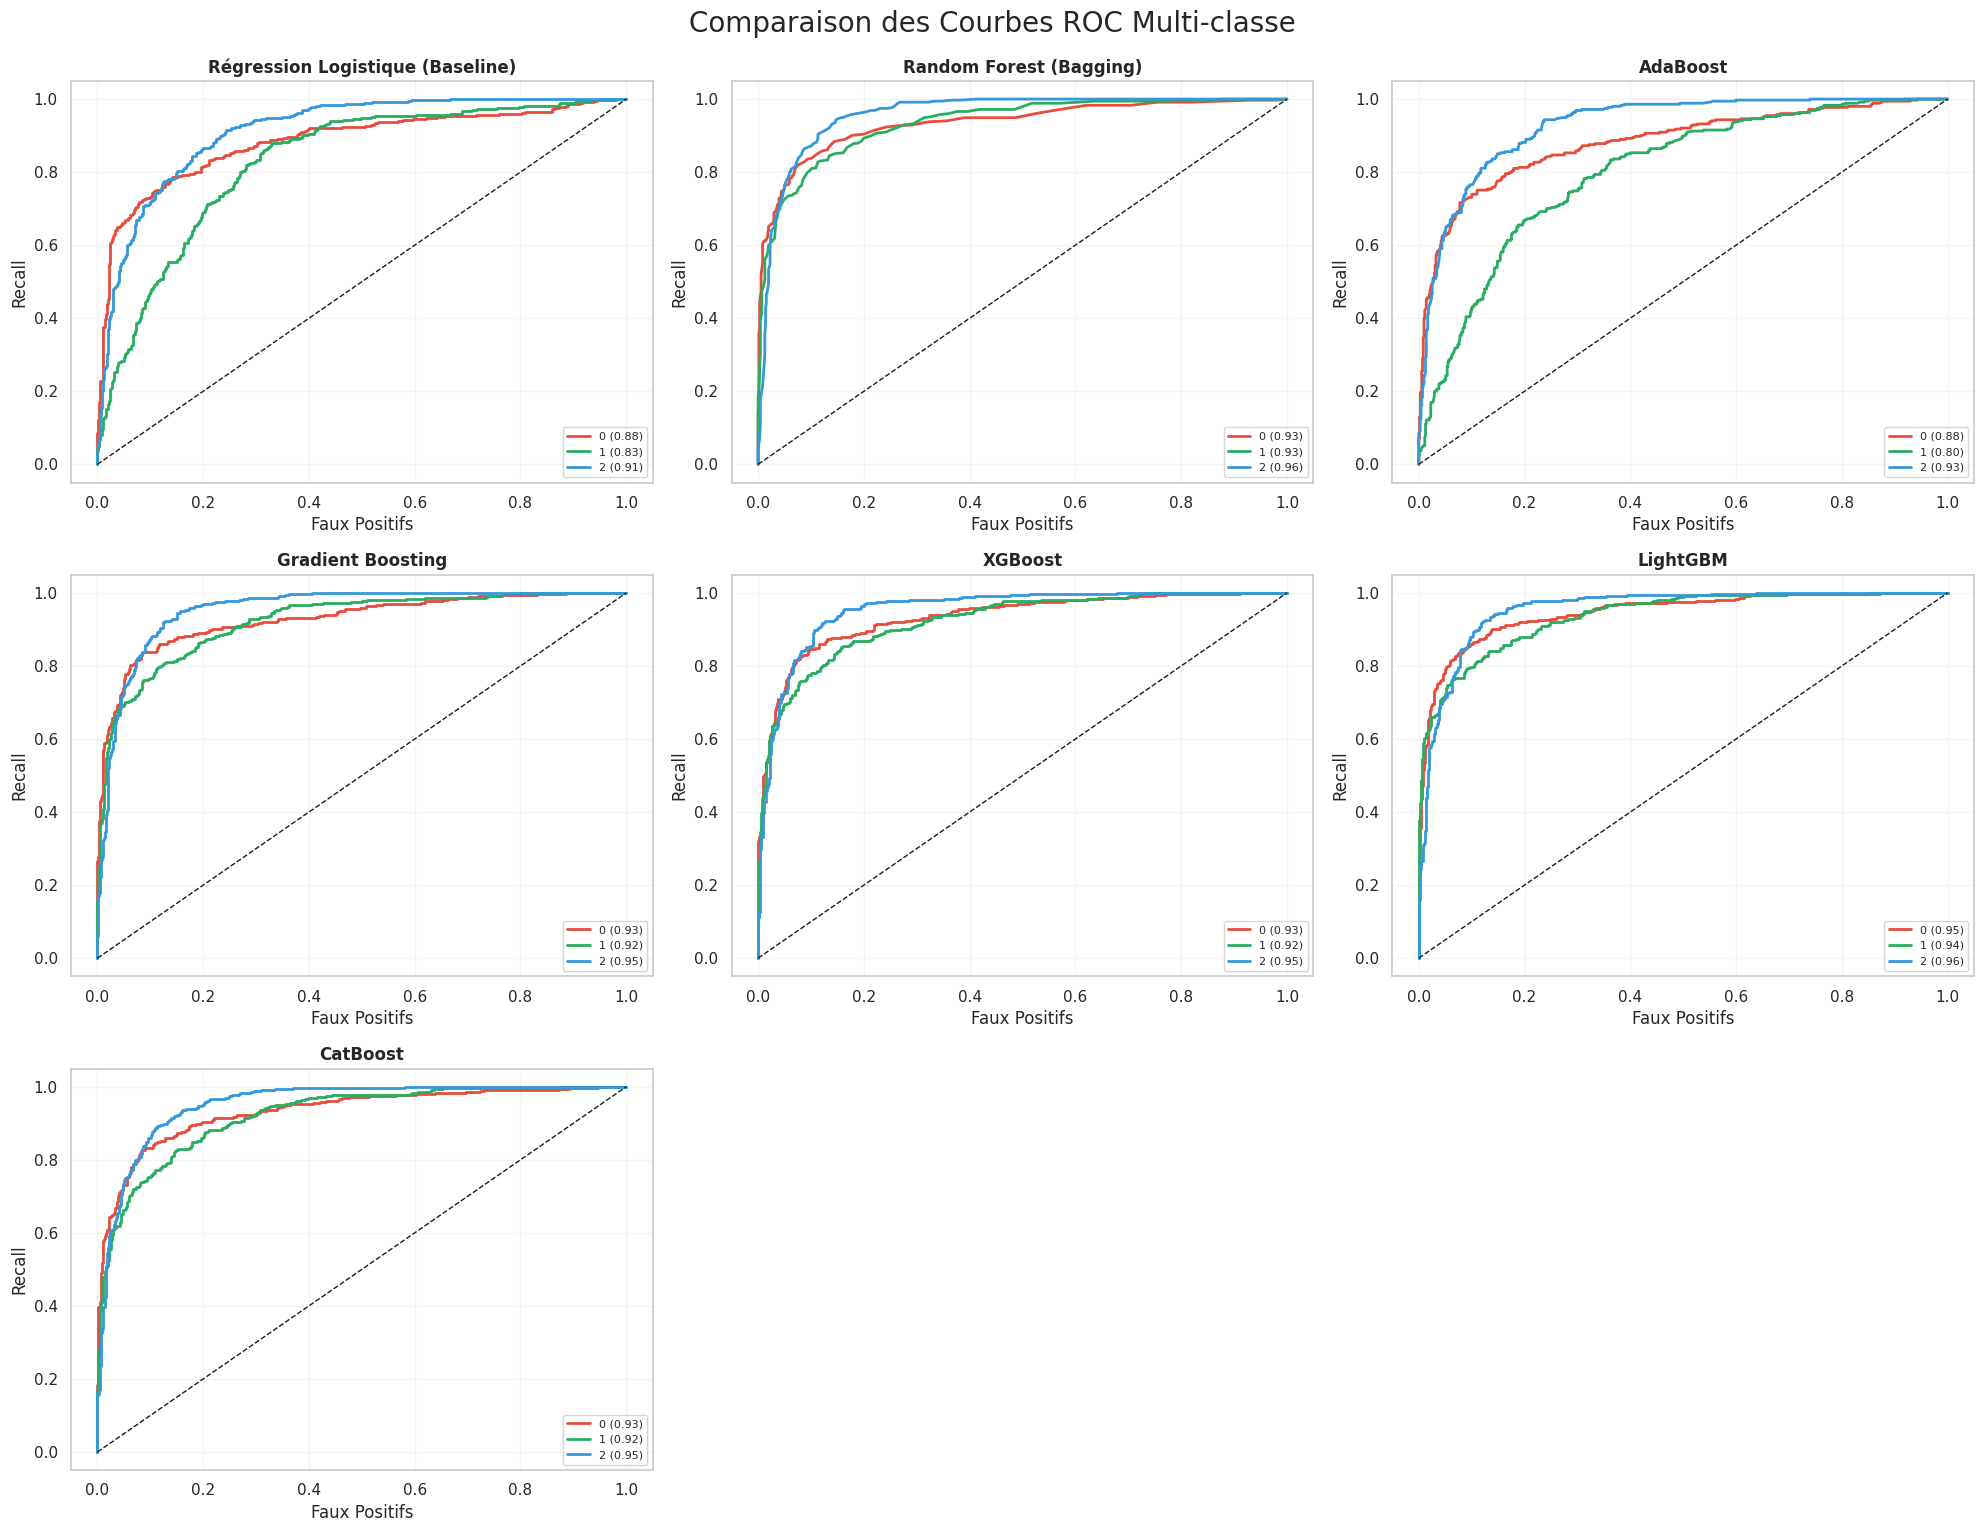

In [16]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# On binarise le jeu de test pour le ROC multiclasse
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 15))
axes = axes.flatten()
couleurs = ['#e74c3c', '#27ae60', '#3498db']

print("📉 Génération des courbes ROC détaillées...")

for i, (nom, (m, must_scale)) in enumerate(config_models.items()):
    # Sélection de la donnée de test
    X_ts = X_test_scaled if must_scale else X_test_raw
    y_score = m.predict_proba(X_ts)

    for c in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], y_score[:, c])
        score_auc = auc(fpr, tpr)
        axes[i].plot(fpr, tpr, color=couleurs[c], lw=2,
                     label=f'{le.classes_[c]} ({score_auc:.2f})')

    axes[i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[i].set_title(nom, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Faux Positifs')
    axes[i].set_ylabel('Recall')
    axes[i].legend(loc="lower right", fontsize=8)
    axes[i].grid(alpha=0.2)

# Nettoyage des axes vides
for j in range(len(config_models), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle("Comparaison des Courbes ROC Multi-classe", fontsize=20, y=1.02)
plt.show()